In [1]:
import mlflow
import json

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("hw-06-recommenders")

/home/taras-hamkalo/repositories/code/ddw/hamkatar/06/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1778397941738, experiment_id='1', last_update_time=1778397941738, lifecycle_stage='active', name='hw-06-recommenders', tags={}, trace_location=None, workspace='default'>

# Prepare dataset, define helpers for logging to MLflow

In [2]:
import os

import pandas as pd

os.makedirs("../outputs", exist_ok=True)

links = pd.read_csv("../resources/ml-latest-small/links.csv")
tags = pd.read_csv("../resources/ml-latest-small/tags.csv")
movies = pd.read_csv("../resources/ml-latest-small/movies.csv")
ratings = pd.read_csv("../resources/ml-latest-small/ratings.csv")

## Precompute embeddings (used for diversity computation)

In [3]:
from embeddings import compute_movie_embeddings

movies = compute_movie_embeddings(movies_data=movies)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 14867.79it/s]


## MLflow logging helper

In [4]:
import mlflow


def log_to_mlflow(
    run_name,
    model_type,
    test_size_ratio,
    relevance_threshold,
    rating_like_threshold,
    results,
    results_file,
    plot_files,
    other_params,
):
    with mlflow.start_run(run_name=run_name):
        dataset_name = "ml-latest-small"
        split_strategy = "random"

        # ----------------------------------------------------------
        # Parameters
        # ----------------------------------------------------------
        mlflow.log_param("model_type", model_type)
        mlflow.log_param("dataset_name", dataset_name)
        mlflow.log_param("split_strategy", split_strategy)
        mlflow.log_param("test_size_ratio", test_size_ratio)
        mlflow.log_param("ks", str(results["ks"]))

        mlflow.log_param("relevance_threshold", relevance_threshold)
        mlflow.log_param("rating_like_threshold", rating_like_threshold)

        for k, v in other_params.items():
            mlflow.log_param(str(k), str(v))

        mlflow.log_metric("train_size", results["train_size"])
        mlflow.log_metric("test_size", results["test_size"])
        mlflow.log_metric(
            "provided_below_required_recommendations",
            results["below_required_recommendations"]
        )
        mlflow.log_metric(
            "dropped_users_count",
            len(results["dropped_user_ids"])
        )

        mlflow.log_metric(
            "train_duration_seconds",
            results["train_duration"].total_seconds()
        )

        mlflow.log_metric(
            "avg_query_time_500_seconds",
            results["query_time_500"].total_seconds()
        )

        mlflow.log_metric("mrr", results["mrr"])

        # ----------------------------------------------------------
        # Metrics for every k
        # ----------------------------------------------------------
        ks = results["ks"]
        metric_names = [
            "precision",
            "recall",
            "f1",
            "ndcg",
            "diversity",
            "coverage",
        ]

        for metric_name in metric_names:
            metric_values = results[metric_name]

            for idx, k in enumerate(ks):
                mlflow.log_metric(
                    f"{metric_name}_at_{k}",
                    float(metric_values[idx])
                )

        # ----------------------------------------------------------
        # Artifacts
        # ----------------------------------------------------------
        if results_file is not None:
            mlflow.log_artifact(results_file)

        for plot_file in plot_files:
            mlflow.log_artifact(
                plot_file,
                artifact_path="plots"
            )

        print(f"Logged {run_name} to MLflow")


## Json serialization helper

In [5]:
import numpy as np


def to_json_serializable(obj):
    """
    Recursively converts NumPy/Pandas-specific types into plain Python types
    that can be serialized by json.dump().
    """
    if isinstance(obj, dict):
        return {
            key: to_json_serializable(value)
            for key, value in obj.items()
        }

    if isinstance(obj, list):
        return [
            to_json_serializable(item)
            for item in obj
        ]

    if isinstance(obj, tuple):
        return tuple(
            to_json_serializable(item)
            for item in obj
        )

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    # datetime.timedelta -> seconds
    if hasattr(obj, "total_seconds"):
        try:
            return obj.total_seconds()
        except Exception:
            pass

    return obj

## Define parameters

In [6]:
test_size = 0.3
relevance_threshold=3.5
rating_like_threshold=3.5

ks = [1, 3, 5, 10, 15, 25, 35, 50, 100, 500]


## Content based recommender

In [7]:
import json
import src.content_based as cb
import src.evaluation as eval

cbr = cb.ContentBasedRec(rating_like_threshold=rating_like_threshold)
res = eval.evaluate(
    ks=ks,
    recommender=cbr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=relevance_threshold,
    test_size_per_user=test_size,
    seed=42
)


res

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(microseconds=123502),
 'query_time_500': datetime.timedelta(microseconds=26016),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.05289256198347107),
  np.float64(0.03140495867768595),
  np.float64(0.030082644628099172),
  np.float64(0.02710743801652892),
  np.float64(0.024022038567493114),
  np.float64(0.021619834710743805),
  np.float64(0.019976387249114522),
  np.float64(0.01821487603305785),
  np.float64(0.015702479338842976),
  np.float64(0.010482644628099174)],
 'recall': [np.float64(0.003793742100834969),
  np.float64(0.006562930288375577),
  np.float64(0.01025008950995383),
  np.float64(0.019011325591177575),
  np.float64(0.025558699319972806),
  np.float64(0.03869024202322522),
  np.float64(0.047866573836225994),
  np.float64(0.06

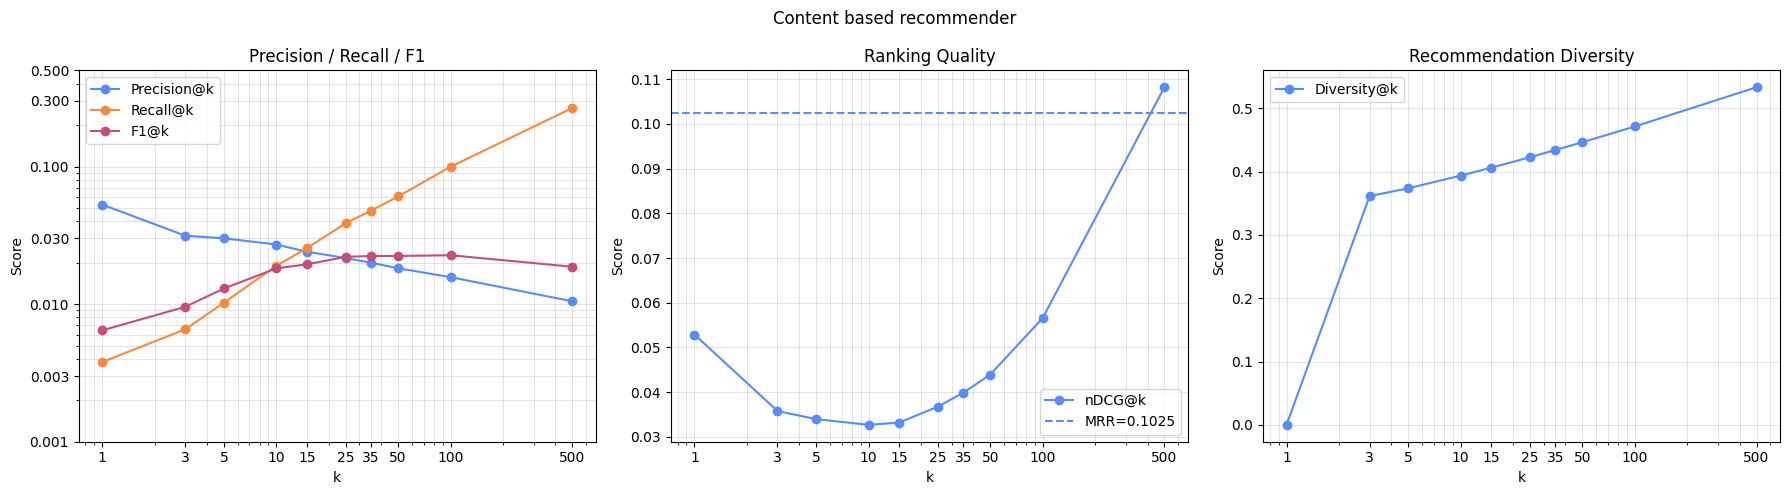

In [8]:
json_res_path = "../outputs/content_based_results.json"
fig_path = "../outputs/content_based_results_plot.png"

with open(json_res_path, "w", encoding="utf-8") as f:
    json.dump(to_json_serializable(res), f, indent=2, ensure_ascii=False)

eval.plot_results_2(results=res, title="Content based recommender", save_path=fig_path)

In [9]:
log_to_mlflow(
    run_name="content_based",
    model_type="content_based",

    test_size_ratio=test_size,
    relevance_threshold=relevance_threshold,
    rating_like_threshold=rating_like_threshold,

    results=res,

    results_file=json_res_path,
    plot_files=[fig_path],

    other_params={}
)

Logged content_based to MLflow
🏃 View run content_based at: http://localhost:5000/#/experiments/1/runs/032d4cd16d1c4c48b591244b7f7a3749
🧪 View experiment at: http://localhost:5000/#/experiments/1


## Collab filtering recommender

In [10]:
import src.collaborative_filtering as cf
import src.evaluation as eval


cfr = cf.CollabFilteringRec()
res = eval.evaluate(
    ks=ks,
    recommender=cfr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=relevance_threshold,
    test_size_per_user=test_size,
    seed=42
)

res

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 271,
 'train_duration': datetime.timedelta(microseconds=66677),
 'query_time_500': datetime.timedelta(microseconds=97608),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.0512396694214876),
  np.float64(0.04683195592286501),
  np.float64(0.04066115702479339),
  np.float64(0.03884297520661157),
  np.float64(0.03889807162534435),
  np.float64(0.038280991735537194),
  np.float64(0.04061393152302244),
  np.float64(0.04333884297520661),
  np.float64(0.04166942148760331),
  np.float64(0.027279338842975207)],
 'recall': [np.float64(0.0035129209106428863),
  np.float64(0.00944979593979452),
  np.float64(0.014822845719638577),
  np.float64(0.031029354334477212),
  np.float64(0.04980152037475458),
  np.float64(0.08026743919875336),
  np.float64(0.11368341807393346),
  np.float64(0.1667469

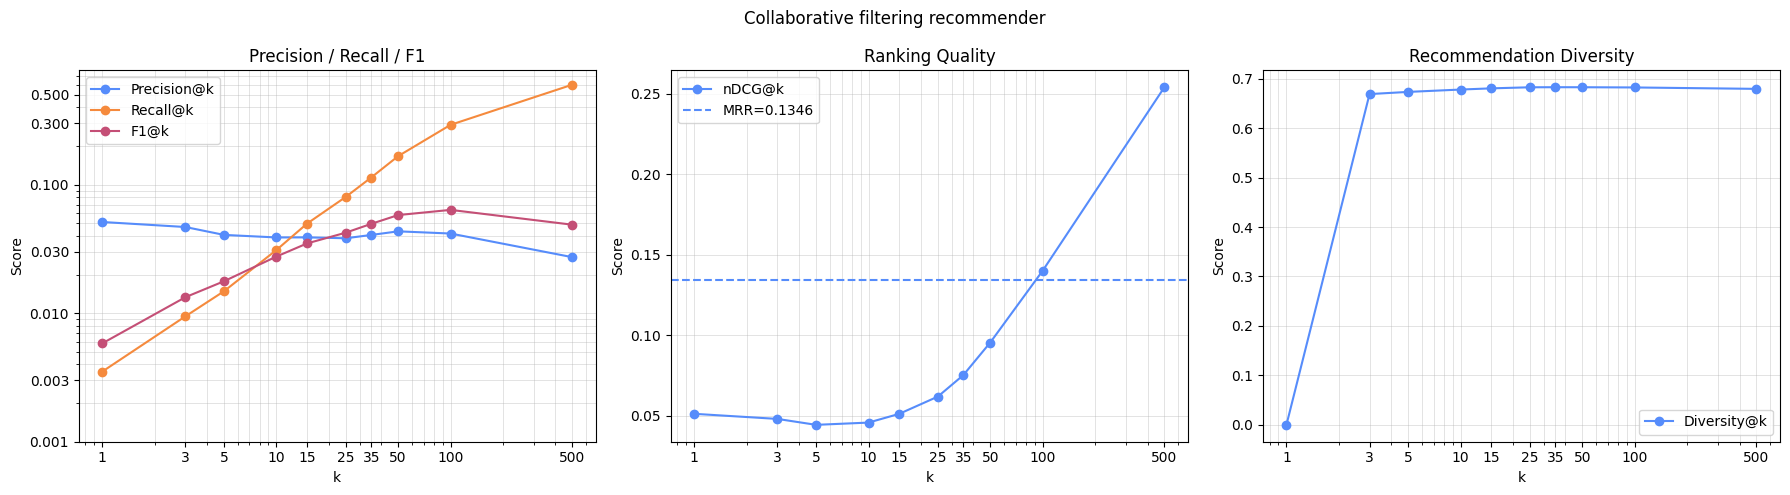

In [11]:
json_res_path = "../outputs/collab_filtering_results.json"
fig_path = "../outputs/collab_filtering_results_plot.png"

with open(json_res_path, "w", encoding="utf-8") as f:
    json.dump(to_json_serializable(res), f, indent=2, ensure_ascii=False)

eval.plot_results_2(results=res, title="Collaborative filtering recommender", save_path=fig_path)


In [12]:
log_to_mlflow(
    run_name="collaborative_filtering",
    model_type="collaborative_filtering",

    test_size_ratio=test_size,
    relevance_threshold=relevance_threshold,
    rating_like_threshold=rating_like_threshold,

    results=res,

    results_file=json_res_path,
    plot_files=[fig_path],

    other_params={}
)


Logged collaborative_filtering to MLflow
🏃 View run collaborative_filtering at: http://localhost:5000/#/experiments/1/runs/27b69b3d7a4e48ed931a548d9f9f89d4
🧪 View experiment at: http://localhost:5000/#/experiments/1


## Hybrid recommender

In [13]:
enlarge_candidate_pool_times=3.5

### Content based then collab filtering

In [14]:
import src.hybrid as h
import src.evaluation as eval


hr = h.HybridRec(
    cbr=cbr,
    cfr=cfr,
    use_content_first=True,
    enlarge_candidate_pool_times=enlarge_candidate_pool_times,
)

res = eval.evaluate(
    ks=ks,
    recommender=hr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=relevance_threshold,
    test_size_per_user=test_size,
    seed=42
)

res


{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(microseconds=239697),
 'query_time_500': datetime.timedelta(microseconds=197267),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.06611570247933884),
  np.float64(0.0418732782369146),
  np.float64(0.03768595041322314),
  np.float64(0.03404958677685951),
  np.float64(0.030743801652892564),
  np.float64(0.027834710743801658),
  np.float64(0.026162927981109797),
  np.float64(0.024231404958677687),
  np.float64(0.020578512396694212),
  np.float64(0.01365619834710744)],
 'recall': [np.float64(0.005887009547288621),
  np.float64(0.010051068252493823),
  np.float64(0.015619825055025405),
  np.float64(0.027032705371977855),
  np.float64(0.03641534960695375),
  np.float64(0.05312302908709761),
  np.float64(0.06689486674869585),
  np.float64(0.0883

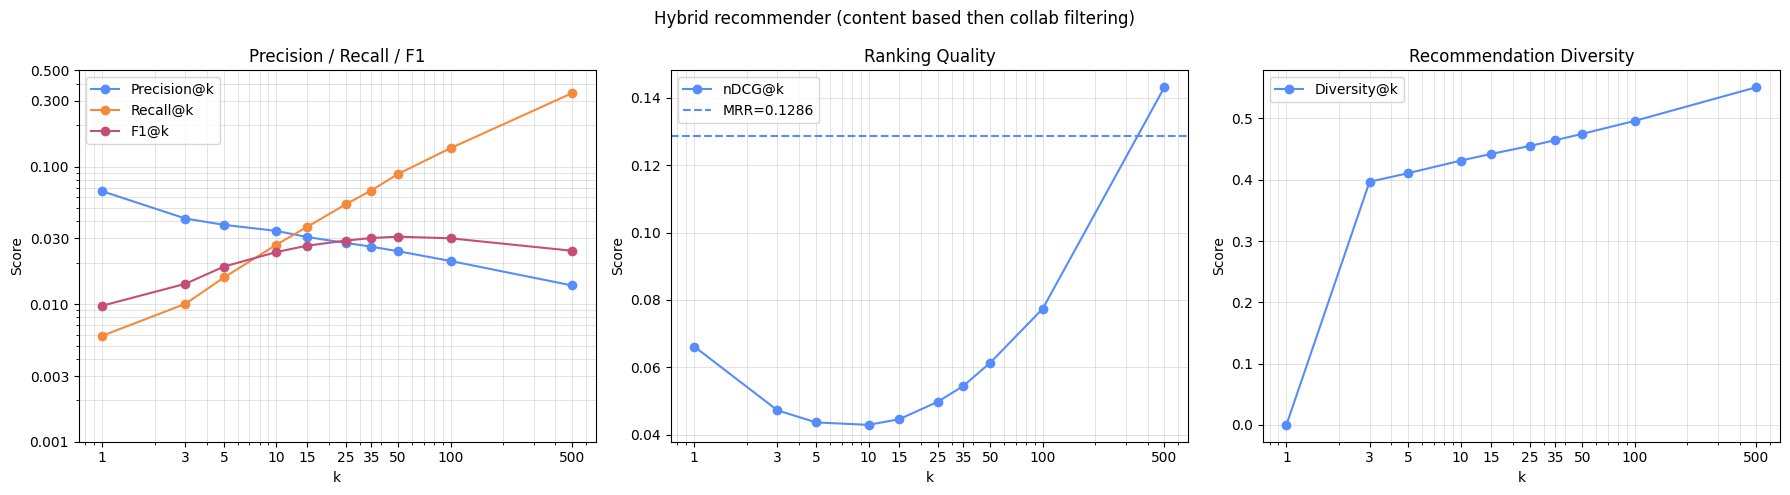

In [15]:
json_res_path = "../outputs/hybrid_content_collab_results.json"
fig_path = "../outputs/hybrid_content_collab_results_plot.png"

with open(json_res_path, "w", encoding="utf-8") as f:
    json.dump(to_json_serializable(res), f, indent=2, ensure_ascii=False)

eval.plot_results_2(results=res, title="Hybrid recommender (content based then collab filtering)", save_path=fig_path)


In [16]:
log_to_mlflow(
    run_name="hybrid_content_collab",
    model_type="hybrid (content based then collab filtering)",

    test_size_ratio=test_size,
    relevance_threshold=relevance_threshold,
    rating_like_threshold=rating_like_threshold,

    results=res,

    results_file=json_res_path,
    plot_files=[fig_path],

    other_params={"enlarge_candidate_pool_times": enlarge_candidate_pool_times}
)



Logged hybrid_content_collab to MLflow
🏃 View run hybrid_content_collab at: http://localhost:5000/#/experiments/1/runs/35ae8f8d988e4f32bac828a441dd454e
🧪 View experiment at: http://localhost:5000/#/experiments/1


### Collab filtering then content based

In [17]:
import src.hybrid as h
import src.evaluation as eval

hr = h.HybridRec(
    cbr=cbr,
    cfr=cfr,
    use_content_first=False,
    enlarge_candidate_pool_times=enlarge_candidate_pool_times,
)

res = eval.evaluate(
    ks=ks,
    recommender=hr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=relevance_threshold,
    test_size_per_user=test_size,
    seed=42
)


res

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 271,
 'train_duration': datetime.timedelta(microseconds=211492),
 'query_time_500': datetime.timedelta(microseconds=99709),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.09256198347107437),
  np.float64(0.08099173553719008),
  np.float64(0.0806611570247934),
  np.float64(0.07338842975206612),
  np.float64(0.06909090909090909),
  np.float64(0.06737190082644628),
  np.float64(0.0658323494687131),
  np.float64(0.06297520661157024),
  np.float64(0.05514049586776859),
  np.float64(0.029530578512396693)],
 'recall': [np.float64(0.011303292443732184),
  np.float64(0.026406855135221223),
  np.float64(0.039861081648534),
  np.float64(0.06819795438282147),
  np.float64(0.09224774466566774),
  np.float64(0.13631276082696472),
  np.float64(0.17628992800121665),
  np.float64(0.233448903763

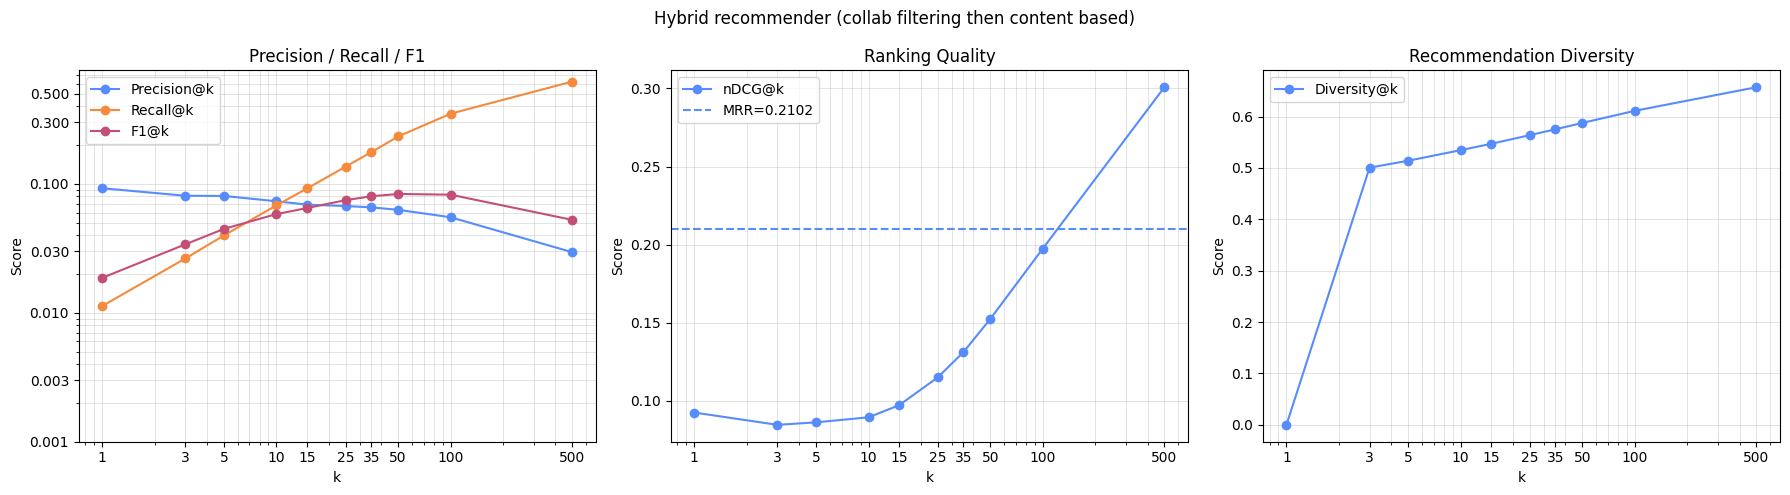

In [18]:
json_res_path = "../outputs/hybrid_collab_content_results.json"
fig_path = "../outputs/hybrid_collab_content_results_plot.png"

with open(json_res_path, "w", encoding="utf-8") as f:
    json.dump(to_json_serializable(res), f, indent=2, ensure_ascii=False)

eval.plot_results_2(results=res, title="Hybrid recommender (collab filtering then content based)", save_path=fig_path)



In [19]:
log_to_mlflow(
    run_name="hybrid_collab_content",
    model_type="hybrid (collab filtering then content based)",

    test_size_ratio=test_size,
    relevance_threshold=relevance_threshold,
    rating_like_threshold=rating_like_threshold,

    results=res,

    results_file=json_res_path,
    plot_files=[fig_path],

    other_params={"enlarge_candidate_pool_times": enlarge_candidate_pool_times}
)



Logged hybrid_collab_content to MLflow
🏃 View run hybrid_collab_content at: http://localhost:5000/#/experiments/1/runs/8a0774e0cf2740e889b9a12ab3b02d29
🧪 View experiment at: http://localhost:5000/#/experiments/1


# TF Framework

In [20]:
embedding_dim=64
epochs=5
batch_size=1024
learning_rate=0.05

In [21]:

import tf_framework as tff
import src.evaluation as eval

tffr = tff.TfFrameworkRec(
    rating_like_threshold=rating_like_threshold,
    embedding_dim=embedding_dim,
    epochs=epochs,
    batch_size=batch_size,
    learning_rate=learning_rate,
    verbose=0,
)

res = eval.evaluate(
    recommender=tffr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=relevance_threshold,
    test_size_per_user=test_size,
    seed=42
)

res


I0000 00:00:1778399680.532566   20786 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778399680.567293   20786 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1778399681.468756   20786 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1778399681.468971   20786 cudart_stub.cc:31] Could not find cuda drivers on your machine, 

{'train_size': 70316,
 'test_size': 30520,
 'dropped_user_ids': [np.int64(54),
  np.int64(150),
  np.int64(214),
  np.int64(333),
  np.int64(442)],
 'below_required_recommendations': 0,
 'train_duration': datetime.timedelta(seconds=11, microseconds=907319),
 'query_time_500': datetime.timedelta(microseconds=16113),
 'ks': [1, 3, 5, 10, 15, 25, 35, 50, 100, 500],
 'precision': [np.float64(0.13388429752066117),
  np.float64(0.13498622589531678),
  np.float64(0.12264462809917354),
  np.float64(0.11504132231404961),
  np.float64(0.10225895316804408),
  np.float64(0.09209917355371901),
  np.float64(0.08387249114521843),
  np.float64(0.07454545454545455),
  np.float64(0.05857851239669421),
  np.float64(0.025226446280991736)],
 'recall': [np.float64(0.009420516569695562),
  np.float64(0.027950778547438607),
  np.float64(0.0402381226308853),
  np.float64(0.07351182978988703),
  np.float64(0.09695060975169356),
  np.float64(0.1390866642269977),
  np.float64(0.1739548509058934),
  np.float64(0.2

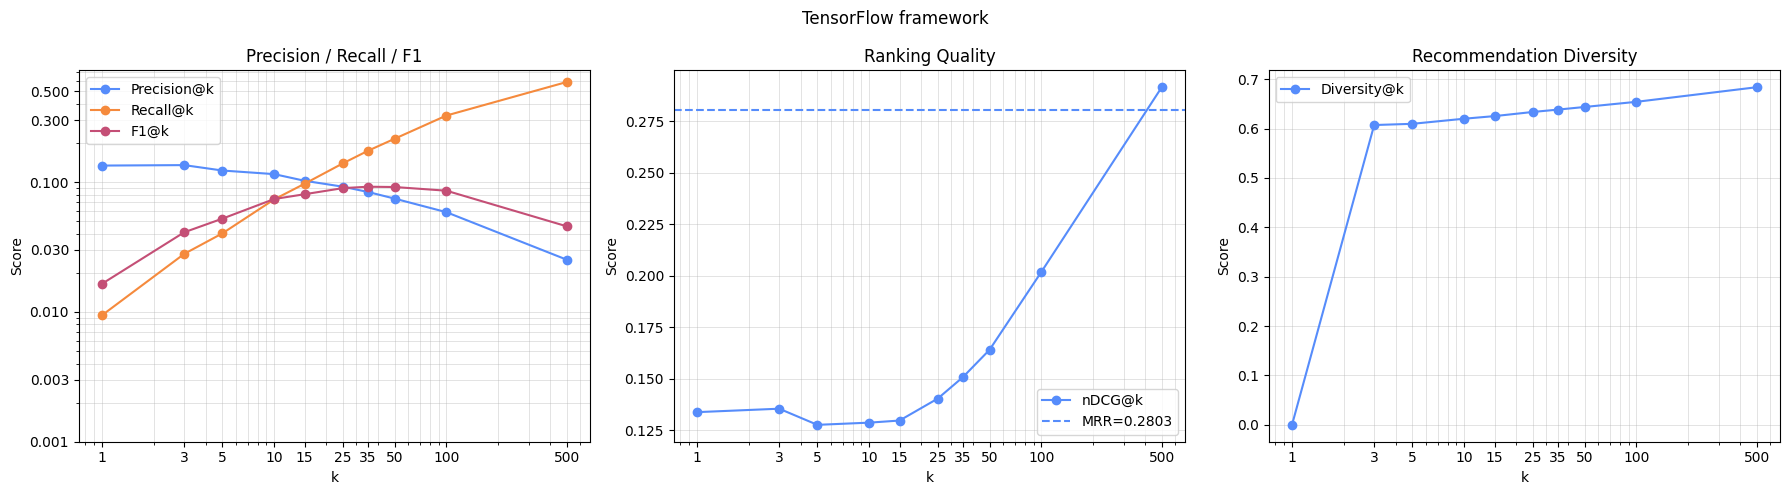

In [22]:
json_res_path = "../outputs/tf_framework_results.json"
fig_path = "../outputs/tf_framework_results_plot.png"

with open(json_res_path, "w", encoding="utf-8") as f:
    json.dump(to_json_serializable(res), f, indent=2, ensure_ascii=False)

eval.plot_results_2(results=res, title="TensorFlow framework", save_path=fig_path)


In [23]:
log_to_mlflow(
    run_name="tensor_flow",
    model_type="tensor flow recommenders framework",

    test_size_ratio=test_size,
    relevance_threshold=relevance_threshold,
    rating_like_threshold=rating_like_threshold,

    results=res,

    results_file=json_res_path,
    plot_files=[fig_path],

    other_params={
        "embedding_dim": 64,
        "epochs": 5,
        "batch_size": 1024,
        "learning_rate": 0.05
    }
)



Logged tensor_flow to MLflow
🏃 View run tensor_flow at: http://localhost:5000/#/experiments/1/runs/8d40dd4c4cb64344b49a787abaa8c53b
🧪 View experiment at: http://localhost:5000/#/experiments/1
